# Data Preprocessing & Exploratory Data Analysis (EDA)

**Dataset:** Iris Flower Dataset  
**Objective:** Clean the data, inspect summary statistics, identify potential outliers, and visualize patterns.

The Iris dataset contains 150 flower samples, four numeric measurements, and a species label. Source: [UCI Machine Learning Repository – Iris](https://archive.ics.uci.edu/dataset/53/iris).


## 1. Import libraries
If any library is missing, install it in your environment with `pip install pandas numpy matplotlib seaborn scikit-learn`.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris

sns.set_theme(style="whitegrid")


## 2. Load the dataset

In [ ]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df = df.rename(columns={
    'sepal length (cm)': 'sepal_length_cm',
    'sepal width (cm)': 'sepal_width_cm',
    'petal length (cm)': 'petal_length_cm',
    'petal width (cm)': 'petal_width_cm',
    'target': 'species_id'
})
df['species'] = df['species_id'].map(dict(enumerate(iris.target_names)))
df = df.drop(columns='species_id')

print('Dataset shape:', df.shape)
display(df.head())
print('\nData types:')
print(df.dtypes)


Dataset shape: (150, 5)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Data types:
sepal_length_cm    float64
sepal_width_cm     float64
petal_length_cm    float64
petal_width_cm     float64
species             object
dtype: object
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## 3. Data quality checks: missing values and duplicates

In [ ]:
print('Missing values per column:')
print(df.isnull().sum())

duplicate_count = df.duplicated().sum()
print('\nDuplicate rows:', duplicate_count)

# Handle missing numeric values with the column median, if any exist.
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

# Remove exact duplicate rows.
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after cleaning:', df.shape)


Missing values per column:
sepal_length_cm    0
sepal_width_cm     0
petal_length_cm    0
petal_width_cm     0
species            0
dtype: int64

Duplicate rows: 1
Shape after cleaning: (149, 5)


## 4. Outlier detection using the IQR method

The IQR method flags values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR. A flagged value is not automatically an error, so this notebook reports potential outliers rather than deleting them without justification.

In [ ]:
outlier_summary = {}
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (df[col] < lower) | (df[col] > upper)
    outlier_summary[col] = int(mask.sum())
    print(f'{col}: lower={lower:.2f}, upper={upper:.2f}, potential outliers={mask.sum()}')

print('\nPotential outlier counts:', outlier_summary)


sepal_length_cm: lower=3.15, upper=8.35, potential outliers=0
sepal_width_cm: lower=2.05, upper=4.05, potential outliers=4
petal_length_cm: lower=-3.65, upper=10.35, potential outliers=0
petal_width_cm: lower=-1.95, upper=4.05, potential outliers=0

Potential outlier counts: {'sepal_length_cm': 0, 'sepal_width_cm': 4, 'petal_length_cm': 0, 'petal_width_cm': 0}


## 5. Summary statistics

In [ ]:
display(df[numeric_cols].describe().round(2))
print('\nSpecies counts:')
display(df['species'].value_counts().rename_axis('species').to_frame('count'))


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
count,149.00,149.00,149.00,149.00
mean,5.84,3.06,3.75,1.19
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.30,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50



Species counts:


,count
species,
setosa,50
versicolor,50
virginica,49


## 6. Visualizations

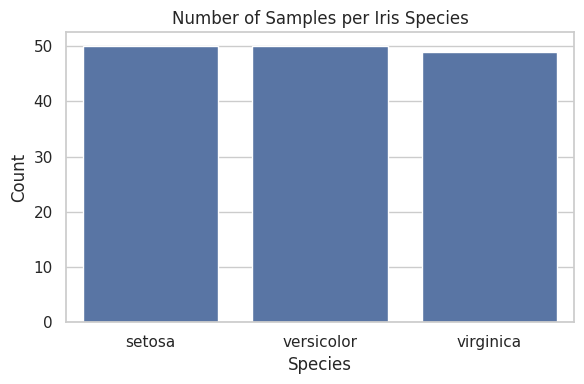

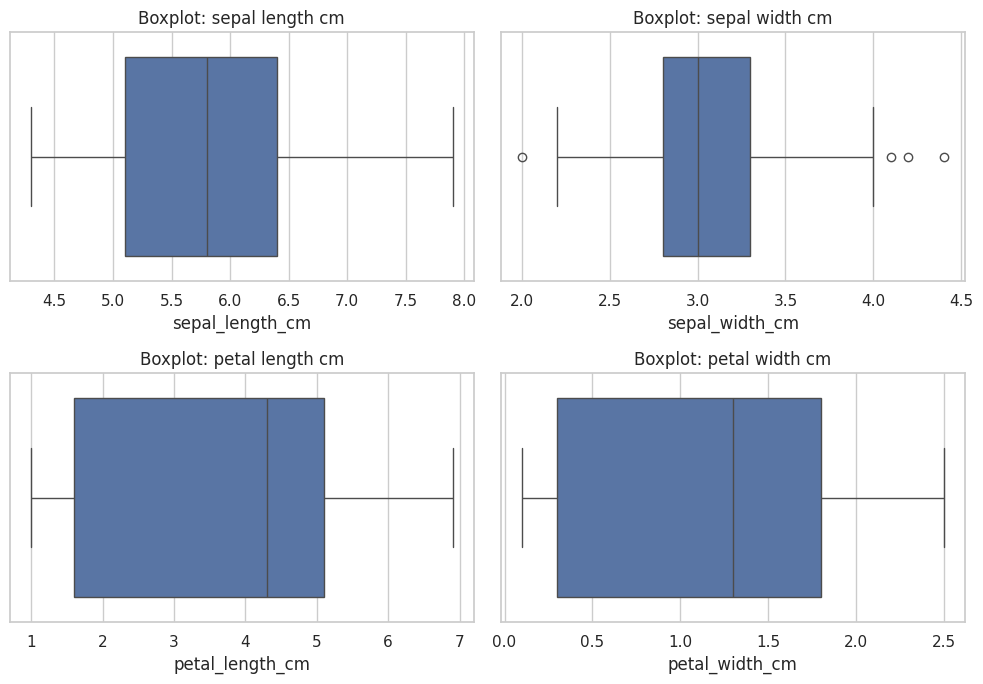

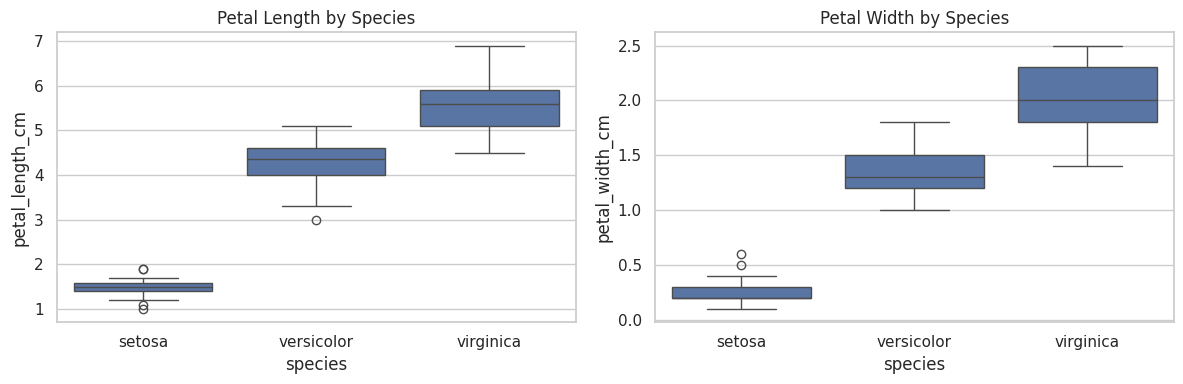

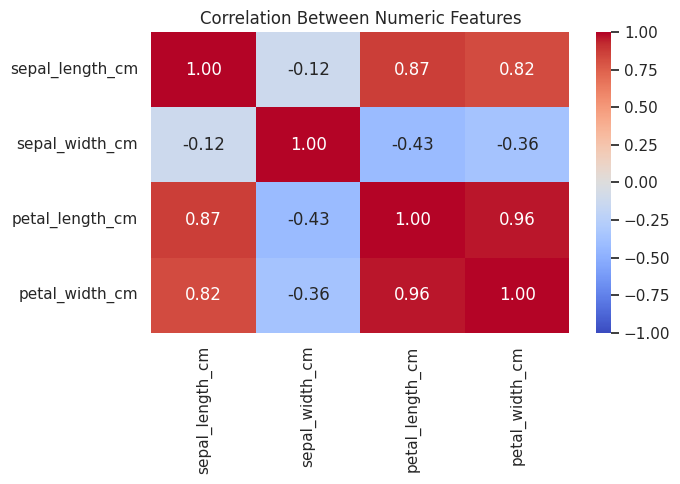

In [ ]:
# Species distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='species')
plt.title('Number of Samples per Iris Species')
plt.xlabel('Species')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# Feature distributions and potential outliers
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for col, ax in zip(numeric_cols, axes.flatten()):
    sns.boxplot(data=df, x=col, ax=ax)
    ax.set_title(f'Boxplot: {col.replace("_", " ")}')
plt.tight_layout()
plt.show()

# Compare petal measurements by species
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='species', y='petal_length_cm', ax=axes[0])
axes[0].set_title('Petal Length by Species')
sns.boxplot(data=df, x='species', y='petal_width_cm', ax=axes[1])
axes[1].set_title('Petal Width by Species')
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Between Numeric Features')
plt.tight_layout()
plt.show()


## 7. Findings and conclusion

In [ ]:
print(f'Final number of rows: {len(df)}')
print(f'Final number of columns: {len(df.columns)}')
print('Missing values after cleaning:', int(df.isnull().sum().sum()))
print('Duplicate rows after cleaning:', int(df.duplicated().sum()))

print('\nMean measurements by species:')
display(df.groupby('species')[numeric_cols].mean().round(2))


Final number of rows: 149
Final number of columns: 5
Missing values after cleaning: 0
Duplicate rows after cleaning: 0

Mean measurements by species:


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.60,2.98,5.56,2.03


### Short report

The Iris dataset was selected for this analysis. It contains measurements of sepal length, sepal width, petal length, and petal width, along with the flower species. The dataset was checked for missing values and duplicate records. Missing numeric values, if present, were filled using the median, and exact duplicate rows were removed. Potential outliers were identified with the IQR method and reviewed rather than automatically deleted.

Summary statistics were calculated to understand the range, average, and spread of the measurements. Count plots, boxplots, and a correlation heatmap were used to explore the data. The species distribution is balanced in the standard Iris dataset, with 50 samples per species. Petal measurements generally help distinguish the species more clearly than sepal measurements. The charts and printed tables above provide the exact results from the run.

**Dataset reference:** Fisher, R. A. (1936). *Iris*. UCI Machine Learning Repository. https://doi.org/10.24432/C56C76
